In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import textwrap

# Carga del dataset 05015 (Comunidades) Victimizaciones de infracciones penales relacionadas con cibercriminalidad desglosado por grupo penal
ruta_05015 = "../data/05015 (Comunidades) Victimizaciones de infracciones penales relacionadas con cibercriminalidad desglosado por grupo penal.csv"
df_vic = pd.read_csv(ruta_05015, sep=";", thousands=".")

df_vic


,Comunidades autónomas,Grupo penal,Grupo edad,Sexo,periodo,Total
0,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,Menores de edad,Masculino,2025,258
1,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,Menores de edad,Masculino,2024,231
2,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,Menores de edad,Masculino,2023,253
3,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,Menores de edad,Masculino,2022,112
4,TOTAL NACIONAL,ACCESO E INTERCEPTACIÓN ILÍCITA,Menores de edad,Masculino,2021,78
...,...,...,...,...,...,...
95035,DESCONOCIDA,TOTAL grupo penal,TOTAL edad,Total sexos,2015,0
95036,DESCONOCIDA,TOTAL grupo penal,TOTAL edad,Total sexos,2014,0
95037,DESCONOCIDA,TOTAL grupo penal,TOTAL edad,Total sexos,2013,0
95038,DESCONOCIDA,TOTAL grupo penal,TOTAL edad,Total sexos,2012,0


In [2]:
df_vic.info()

<class 'pandas.DataFrame'>
RangeIndex: 95040 entries, 0 to 95039
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Comunidades autónomas  95040 non-null  str  
 1   Grupo penal            95040 non-null  str  
 2   Grupo edad             95040 non-null  str  
 3   Sexo                   95040 non-null  str  
 4   periodo                95040 non-null  int64
 5   Total                  95040 non-null  int64
dtypes: int64(2), str(4)
memory usage: 4.4 MB


In [2]:
df_vic.columns



Index(['Comunidades autónomas', 'Grupo penal', 'Grupo edad', 'Sexo', 'periodo',
       'Total'],
      dtype='str')

In [4]:
df_vic["Comunidades autónomas"].unique()

<StringArray>
[              'TOTAL NACIONAL',                    'ANDALUCÍA',
                       'ARAGÓN',     'ASTURIAS (PRINCIPADO DE)',
              'BALEARS (ILLES)',                     'CANARIAS',
                    'CANTABRIA',              'CASTILLA Y LEÓN',
         'CASTILLA - LA MANCHA',                     'CATALUÑA',
         'COMUNITAT VALENCIANA',                  'EXTREMADURA',
                      'GALICIA',        'MADRID (COMUNIDAD DE)',
           'MURCIA (REGIÓN DE)', 'NAVARRA (COMUNIDAD FORAL DE)',
                   'PAÍS VASCO',                   'RIOJA (LA)',
     'CIUDAD AUTÓNOMA DE CEUTA',   'CIUDAD AUTÓNOMA DE MELILLA',
             'EN EL EXTRANJERO',                  'DESCONOCIDA']
Length: 22, dtype: str

In [5]:
df_vic["Grupo penal"].unique()

<StringArray>
[          'ACCESO  E INTERCEPTACIÓN ILÍCITA',
                      'AMENAZAS Y COACCIONES',
                            'CONTRA EL HONOR',
 'CONTRA LA PROPIEDAD INDUSTRIAL/INTELECTUAL',
                           'DELITOS SEXUALES',
                  'FALSIFICACIÓN INFORMÁTICA',
                         'FRAUDE INFORMÁTICO',
 'INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA',
                          'TOTAL grupo penal']
Length: 9, dtype: str

In [6]:
df_vic["Grupo edad"].unique()

<StringArray>
[   'Menores de edad',    'De 18 a 25 años',    'De 26 a 40 años',
    'De 41 a 50 años',    'De 51 a 65 años', 'Mayores de 65 años',
   'Edad desconocida',         'TOTAL edad']
Length: 8, dtype: str

In [7]:
df_vic["Sexo"].unique()

<StringArray>
['Masculino', 'Femenino', 'Se desconoce', 'Total sexos']
Length: 4, dtype: str

In [8]:
df_vic["periodo"].unique()

array([2025, 2024, 2023, 2022, 2021, 2020, 2019, 2018, 2017, 2016, 2015,
       2014, 2013, 2012, 2011])

In [34]:


# Filtrados
df_filtrado = df_vic[
    (df_vic["Comunidades autónomas"] != "TOTAL NACIONAL") & 
    (df_vic["Grupo penal"] != "TOTAL tipo hecho") &
    (df_vic["Grupo penal"] != "TOTAL grupo penal") &
    (df_vic["Sexo"] != "Total sexos" ) &
    (df_vic["Grupo edad"] != "TOTAL edad" ) 
]
df_filtrado

,Comunidades autónomas,Grupo penal,Grupo edad,Sexo,periodo,Total
4320,ANDALUCÍA,ACCESO E INTERCEPTACIÓN ILÍCITA,Menores de edad,Masculino,2025,55
4321,ANDALUCÍA,ACCESO E INTERCEPTACIÓN ILÍCITA,Menores de edad,Masculino,2024,42
4322,ANDALUCÍA,ACCESO E INTERCEPTACIÓN ILÍCITA,Menores de edad,Masculino,2023,58
4323,ANDALUCÍA,ACCESO E INTERCEPTACIÓN ILÍCITA,Menores de edad,Masculino,2022,14
4324,ANDALUCÍA,ACCESO E INTERCEPTACIÓN ILÍCITA,Menores de edad,Masculino,2021,10
...,...,...,...,...,...,...
94480,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,Edad desconocida,Se desconoce,2015,0
94481,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,Edad desconocida,Se desconoce,2014,0
94482,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,Edad desconocida,Se desconoce,2013,0
94483,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,Edad desconocida,Se desconoce,2012,0


In [35]:


# Guardar el CSV 
df_filtrado.to_csv("../data/dataset5_victimizaciones.csv", sep=";")

In [ ]:
# Víctimas por Sexo y Grupo de Edad

In [36]:


# Víctimas agrupadas por "Sexo" 
vic_sexo = df_filtrado.groupby("Sexo")["Total"].sum().sort_values(ascending=False)

vic_sexo_porcentaje = (vic_sexo / vic_sexo.sum() * 100).round()

print(vic_sexo)
print(vic_sexo_porcentaje)

Sexo
Masculino       1288616
Femenino        1200413
Se desconoce       1641
Name: Total, dtype: int64
Sexo
Masculino       52.0
Femenino        48.0
Se desconoce     0.0
Name: Total, dtype: float64


In [37]:

# Víctimas agrupadas por "Grupo edad"

vic_edad = df_filtrado.groupby("Grupo edad")["Total"].sum()

vic_edad_porcentaje = (vic_edad / vic_edad.sum() * 100).round()


print(vic_edad)
print(vic_edad_porcentaje)


Grupo edad
De 18 a 25 años       326268
De 26 a 40 años       726870
De 41 a 50 años       581731
De 51 a 65 años       575894
Edad desconocida        3895
Mayores de 65 años    230754
Menores de edad        45258
Name: Total, dtype: int64
Grupo edad
De 18 a 25 años       13.0
De 26 a 40 años       29.0
De 41 a 50 años       23.0
De 51 a 65 años       23.0
Edad desconocida       0.0
Mayores de 65 años     9.0
Menores de edad        2.0
Name: Total, dtype: float64


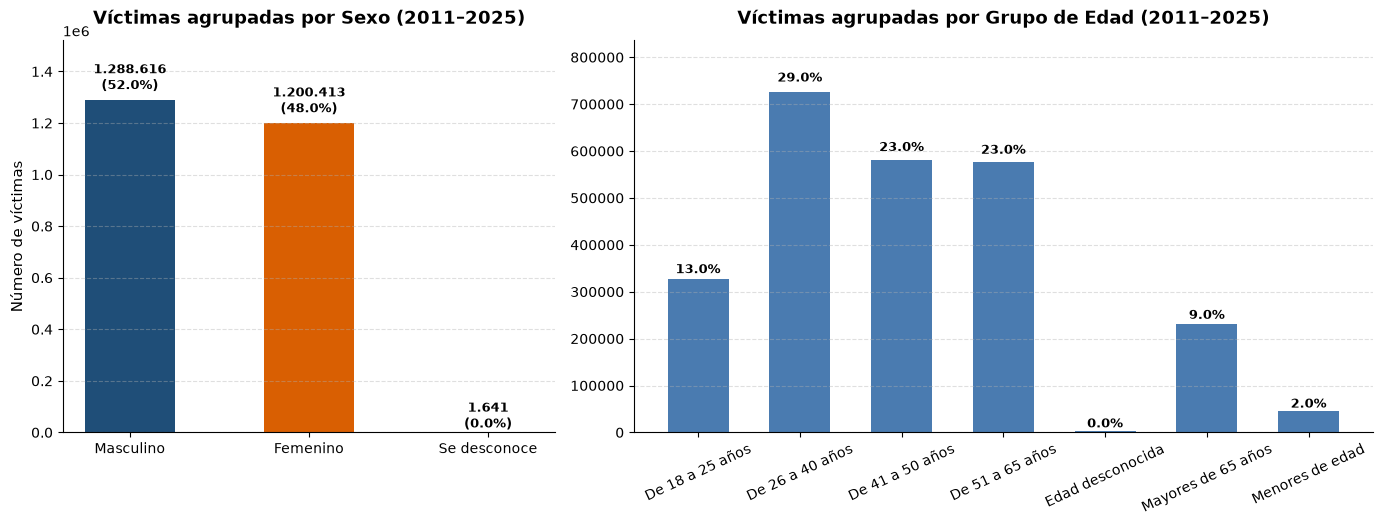

In [38]:

# Gráfico de Víctimas agrupadas por "Sexo" y Víctimas agrupadas por "Grupo edad" )
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.5]})

# Sexo
colores_sexo = ["#1f4e78", "#d95f02", "#7f7f7f"][:len(vic_sexo)]
bars1 = ax1.bar(vic_sexo.index, vic_sexo.values, color=colores_sexo, width=0.5)
ax1.set_title("Víctimas agrupadas por Sexo (2011–2025)", fontsize=13, fontweight="bold", pad=12)
ax1.set_ylabel("Número de víctimas", fontsize=10.5)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.grid(axis="y", linestyle="--", alpha=0.4)

for bar, pct in zip(bars1, vic_sexo_porcentaje.values):
    val = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, val + (val*0.02),
             f"{val:,.0f}\n({pct}%)".replace(",", "."), ha="center", va="bottom", fontsize=9.5, fontweight="bold")
ax1.set_ylim(0, vic_sexo.max() * 1.18)

# Grupo Edad
bars2 = ax2.bar(vic_edad.index, vic_edad.values, color="#4a7bb0", width=0.6)
ax2.set_title("Víctimas agrupadas por Grupo de Edad (2011–2025)", fontsize=13, fontweight="bold", pad=12)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.grid(axis="y", linestyle="--", alpha=0.4)
ax2.tick_params(axis="x", rotation=25)

for bar, pct in zip(bars2, vic_edad_porcentaje.values):
    val = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, val + (val*0.02),
             f"{pct}%", ha="center", va="bottom", fontsize=9.5, fontweight="bold")
ax2.set_ylim(0, vic_edad.max() * 1.15)

plt.tight_layout()
plt.show()


In [39]:
df_filtrado

,Comunidades autónomas,Grupo penal,Grupo edad,Sexo,periodo,Total
4320,ANDALUCÍA,ACCESO E INTERCEPTACIÓN ILÍCITA,Menores de edad,Masculino,2025,55
4321,ANDALUCÍA,ACCESO E INTERCEPTACIÓN ILÍCITA,Menores de edad,Masculino,2024,42
4322,ANDALUCÍA,ACCESO E INTERCEPTACIÓN ILÍCITA,Menores de edad,Masculino,2023,58
4323,ANDALUCÍA,ACCESO E INTERCEPTACIÓN ILÍCITA,Menores de edad,Masculino,2022,14
4324,ANDALUCÍA,ACCESO E INTERCEPTACIÓN ILÍCITA,Menores de edad,Masculino,2021,10
...,...,...,...,...,...,...
94480,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,Edad desconocida,Se desconoce,2015,0
94481,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,Edad desconocida,Se desconoce,2014,0
94482,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,Edad desconocida,Se desconoce,2013,0
94483,DESCONOCIDA,INTERFERENCIA EN LOS DATOS Y EN EL SISTEMA,Edad desconocida,Se desconoce,2012,0


In [40]:
df_filtrado.columns

Index(['Comunidades autónomas', 'Grupo penal', 'Grupo edad', 'Sexo', 'periodo',
       'Total'],
      dtype='str')

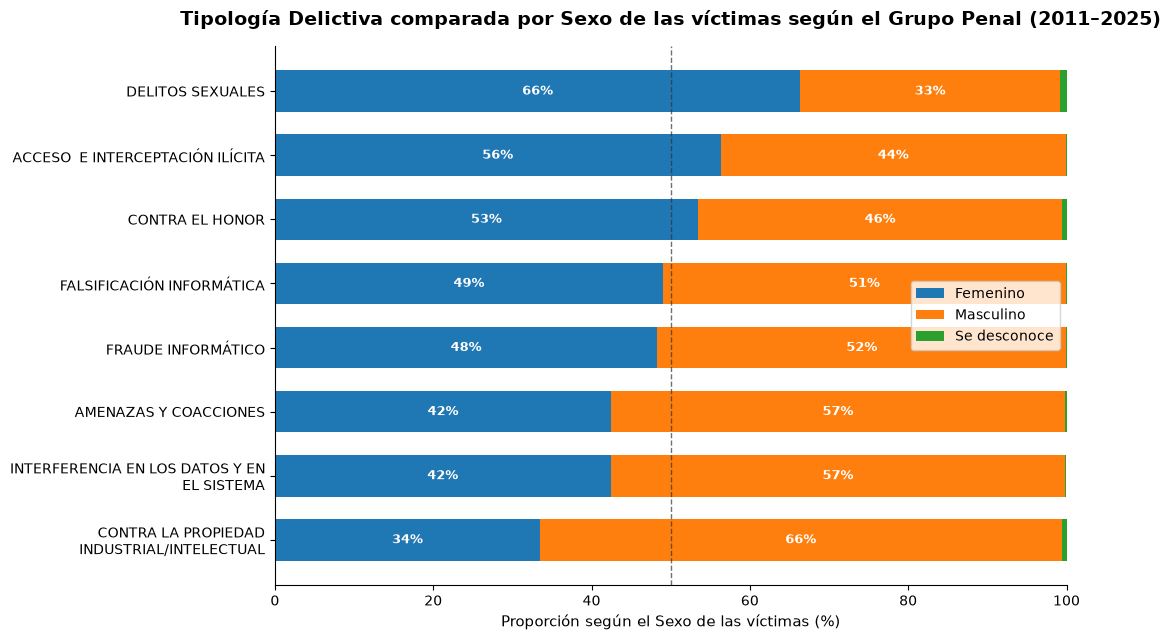

In [42]:
# Comparando Tipología Delictiva con el Sexo de las víctimas 

# Tabla comparativa de Grupo Penal vs Sexo (% por fila)
tabla_grupo_sexo = pd.pivot_table(
    df_filtrado, values="Total", index="Grupo penal", columns="Sexo", aggfunc="sum", fill_value=0
)
tabla_grupo_sexo_porcentaje = tabla_grupo_sexo.div(tabla_grupo_sexo.sum(axis=1), axis=0) * 100

# Ordenar por porcentaje de mujeres (si existe la columna 'Mujeres')
col_mujeres = [c for c in tabla_grupo_sexo_porcentaje.columns if "Femenino" in c][0]
tabla_plot = tabla_grupo_sexo_porcentaje.sort_values(by=col_mujeres, ascending=True)

etiquetas = [textwrap.fill(str(nombre), width=32) for nombre in tabla_plot.index]

fig, ax = plt.subplots(figsize=(11, 6.5))
left_acum = np.zeros(len(tabla_plot))
paleta = {"Mujeres": "#d95f02", "Hombres": "#1f4e78"}

for col in tabla_plot.columns:
    color = paleta.get(col)
    bars = ax.barh(etiquetas, tabla_plot[col], left=left_acum, label=col, color=color, height=0.65)
    
    # Etiquetar porcentajes mayores al 8% dentro de cada segmento
    for i, val in enumerate(tabla_plot[col]):
        if val >= 8:
            ax.text(left_acum[i] + val/2, i, f"{val:.0f}%", va="center", ha="center",
                    color="white", fontweight="bold", fontsize=9.5)
    left_acum += tabla_plot[col].values

ax.axvline(50, color="#333333", linestyle="--", linewidth=1, alpha=0.7)
ax.set_title("Tipología Delictiva comparada por Sexo de las víctimas según el Grupo Penal (2011–2025)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Proporción según el Sexo de las víctimas (%)", fontsize=11)
ax.set_xlim(0, 100)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="center right", frameon=True)

plt.tight_layout()
plt.show()


